In [55]:
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.model_selection import GroupShuffleSplit
from pandas.plotting import scatter_matrix
from sklearn.pipeline import Pipeline, make_pipeline
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer, make_column_selector
from sklearn.impute import SimpleImputer
from sklearn.linear_model import LinearRegression
from sklearn.metrics import root_mean_squared_error, mean_absolute_error, r2_score
from sklearn.ensemble import RandomForestRegressor
from sklearn.model_selection import cross_val_score, GridSearchCV
from sklearn.tree import DecisionTreeRegressor
from sklearn.svm import SVR
from sklearn.cluster import KMeans
from sklearn.metrics.pairwise import rbf_kernel
from scipy.stats import randint


df = pd.read_csv('../../Clean data/df_ml.csv')

df.head()

,folioviv,foliohog,ubica_geo,tam_loc,est_socio,clase_hog,sexo_jefe,edad_jefe,educa_jefe,tot_integ,hombres,mujeres,mayores,menores,p12_64,p65mas,ocupados,percep_ing,perc_ocupa,ing_cor
0,100001901,1,1001,"Mas de 100,000 hab",Medio Alto,Nuclear,Hombre,32,Secundaria,4,2,2,2,2,2,0,2,2,2,138232.38
1,100001902,1,1001,"Mas de 100,000 hab",Medio Alto,Nuclear,Hombre,48,Profesional inc,4,2,2,4,0,4,0,2,2,2,118014.04
2,100001904,1,1001,"Mas de 100,000 hab",Medio Alto,Nuclear,Mujer,60,Secundaria,2,1,1,2,0,2,0,2,2,2,46866.32
3,100001905,1,1001,"Mas de 100,000 hab",Medio Alto,Nuclear,Hombre,43,Prepa comp,4,3,1,4,0,4,0,3,3,3,110430.10
4,100002501,1,1001,"Mas de 100,000 hab",Medio Bajo,Nuclear,Mujer,29,Prepa comp,4,1,3,2,2,2,0,2,2,2,99494.12


In [7]:
df.describe()

,folioviv,foliohog,ubica_geo,edad_jefe,tot_integ,hombres,mujeres,mayores,menores,p12_64,p65mas,ocupados,percep_ing,perc_ocupa,ing_cor
count,8.345400e+04,83454.000000,83454.000000,83454.000000,83454.000000,83454.000000,83454.000000,83454.000000,83454.000000,83454.000000,83454.000000,83454.000000,83454.000000,83454.000000,83454.000000
mean,1.631995e+09,1.014751,16060.190021,51.465047,3.315192,1.592386,1.722805,2.696527,0.618664,2.351763,0.344765,1.573789,2.127903,1.520670,57616.598252
std,9.305905e+08,0.137022,9301.236465,16.168182,1.726216,1.082879,1.150927,1.312653,0.919138,1.447741,0.625418,1.037695,1.098368,0.992427,31731.393603
min,1.000019e+08,1.000000,1001.000000,14.000000,1.000000,0.000000,0.000000,1.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000,0.000000
25%,8.029424e+08,1.000000,8019.000000,39.000000,2.000000,1.000000,1.000000,2.000000,0.000000,1.000000,0.000000,1.000000,1.000000,1.000000,32754.090000
50%,1.605463e+09,1.000000,16024.000000,50.000000,3.000000,1.000000,2.000000,2.000000,0.000000,2.000000,0.000000,1.000000,2.000000,1.000000,51577.310000
75%,2.468080e+09,1.000000,24028.000000,63.000000,4.000000,2.000000,2.000000,3.000000,1.000000,3.000000,1.000000,2.000000,3.000000,2.000000,77609.145000
max,3.260594e+09,4.000000,32056.000000,106.000000,20.000000,10.000000,11.000000,14.000000,9.000000,14.000000,5.000000,11.000000,13.000000,8.000000,143138.190000


In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 83454 entries, 0 to 83453
Data columns (total 20 columns):
 #   Column      Non-Null Count  Dtype  
---  ------      --------------  -----  
 0   folioviv    83454 non-null  int64  
 1   foliohog    83454 non-null  int64  
 2   ubica_geo   83454 non-null  int64  
 3   tam_loc     83454 non-null  object 
 4   est_socio   83454 non-null  object 
 5   clase_hog   83454 non-null  object 
 6   sexo_jefe   83454 non-null  object 
 7   edad_jefe   83454 non-null  int64  
 8   educa_jefe  83454 non-null  object 
 9   tot_integ   83454 non-null  int64  
 10  hombres     83454 non-null  int64  
 11  mujeres     83454 non-null  int64  
 12  mayores     83454 non-null  int64  
 13  menores     83454 non-null  int64  
 14  p12_64      83454 non-null  int64  
 15  p65mas      83454 non-null  int64  
 16  ocupados    83454 non-null  int64  
 17  percep_ing  83454 non-null  int64  
 18  perc_ocupa  83454 non-null  int64  
 19  ing_cor     83454 non-nul

In [8]:
df['folioviv'].nunique()

82425

confirmamos que folioviv + foliohog sea unica

In [14]:
df.duplicated(subset=['folioviv', 'foliohog']).sum()

np.int64(0)

el numero maximo de hogares por vivienda es 4

In [16]:
df['folioviv'].value_counts().head()

folioviv
361119612    4
361119813    4
802698301    4
361119610    4
401320502    4
Name: count, dtype: int64

In [18]:
df['tam_loc'].value_counts()

tam_loc
Menos de 2,500 hab        34551
Mas de 100,000 hab        29063
De 2,500 a 14,999 hab     10239
De 15,000 a 99,999 hab     9601
Name: count, dtype: int64

In [19]:
df['ubica_geo'].value_counts()

ubica_geo
1001     1429
2002     1296
8037     1107
25006    1011
3003      945
         ... 
24009       3
20102       3
20174       2
14050       2
15073       2
Name: count, Length: 1111, dtype: int64

In [21]:
df['est_socio'].value_counts()

est_socio
Medio Bajo    43875
Bajo          18484
Medio Alto    15713
Alto           5382
Name: count, dtype: int64

In [22]:
df['clase_hog'].value_counts()

clase_hog
Nuclear         51443
Ampliado        19143
Unipersonal     12151
Compuesto         469
Corresidente      248
Name: count, dtype: int64

In [24]:
df['educa_jefe'].value_counts()

educa_jefe
Basico              29379
Secundaria          23446
Prepa comp          11611
Profesional comp     7533
Sin Educacion        5310
Prepa inc            2617
Profesional inc      2459
Posgrado             1099
Name: count, dtype: int64

# Crear un train-test split

si se hace un train_test_split aleatorio, un hogar de una vivienda puede quedar en train y el otro en test. Comparten ubicación, estrato y tamaño de localidad, y suelen tener ingresos correlacionados, así que el modelo ve información casi duplicada. Con ~1,000 casos sobre 83k el efecto sería pequeño, pero es fácil de evitar con GroupShuffleSplit, dividiendo el dataset en train/test por viviendas

In [33]:
splitter = GroupShuffleSplit(n_splits=1, test_size=0.2, random_state=42)
train_idx, test_idx = next(splitter.split(df, groups=df['folioviv']))
train_set, test_set = df.iloc[train_idx], df.iloc[test_idx]

train_set.head()

,folioviv,foliohog,ubica_geo,tam_loc,est_socio,clase_hog,sexo_jefe,edad_jefe,educa_jefe,tot_integ,hombres,mujeres,mayores,menores,p12_64,p65mas,ocupados,percep_ing,perc_ocupa,ing_cor
0,100001901,1,1001,"Mas de 100,000 hab",Medio Alto,Nuclear,Hombre,32,Secundaria,4,2,2,2,2,2,0,2,2,2,138232.38
1,100001902,1,1001,"Mas de 100,000 hab",Medio Alto,Nuclear,Hombre,48,Profesional inc,4,2,2,4,0,4,0,2,2,2,118014.04
2,100001904,1,1001,"Mas de 100,000 hab",Medio Alto,Nuclear,Mujer,60,Secundaria,2,1,1,2,0,2,0,2,2,2,46866.32
3,100001905,1,1001,"Mas de 100,000 hab",Medio Alto,Nuclear,Hombre,43,Prepa comp,4,3,1,4,0,4,0,3,3,3,110430.10
4,100002501,1,1001,"Mas de 100,000 hab",Medio Bajo,Nuclear,Mujer,29,Prepa comp,4,1,3,2,2,2,0,2,2,2,99494.12


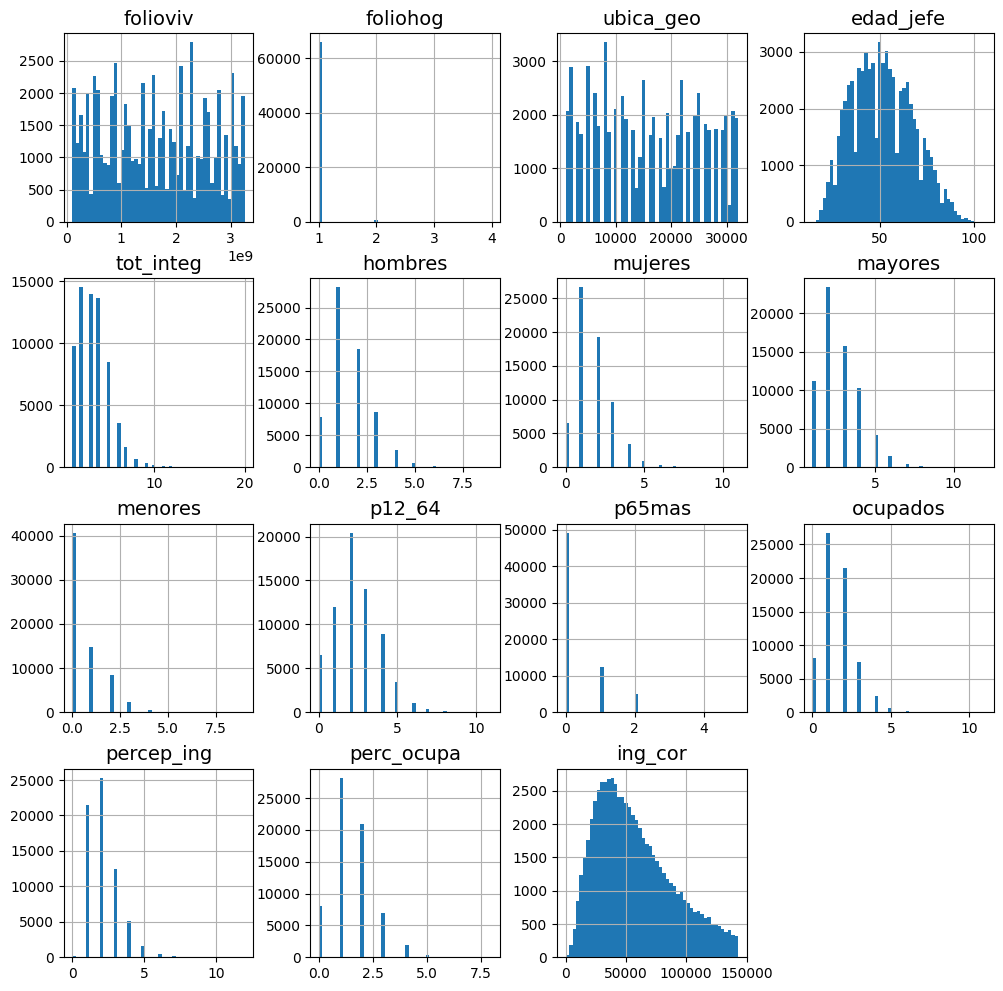

In [43]:
plt.rc('font', size=14)
plt.rc('axes', labelsize=14, titlesize=14)
plt.rc('legend', fontsize=14)
plt.rc('xtick', labelsize=10)
plt.rc('ytick', labelsize=10)

train_set.hist(bins=50, figsize=(12, 12))

plt.show()

comprobamos que no comparten vivienda

In [34]:
test_set['folioviv'].isin(train_set["folioviv"].unique()).sum()

np.int64(0)

Al hacer la distribucion se corre el riesgo de que los conjuntos no sean representativos asi que los compararemos

In [35]:
tabla_comparativa = pd.DataFrame(
    {"train set":train_set['ing_cor'].describe(),
     "test set":test_set['ing_cor'].describe()
    }
    )

tabla_comparativa

,train set,test set
count,66770.000000,16684.000000
mean,57671.862353,57395.429227
std,31779.341813,31538.752254
min,0.000000,0.000000
25%,32721.942500,32848.010000
50%,51668.135000,51232.150000
75%,77839.410000,76714.810000
max,143136.170000,143138.190000


Buscamos alguna correlacion importante entre las variables independientes y la dependiente

In [42]:
corr_matrix = train_set.corr(numeric_only=True)

corr_matrix["ing_cor"].sort_values(ascending=False)

ing_cor       1.000000
perc_ocupa    0.375766
percep_ing    0.363766
ocupados      0.345224
mayores       0.329767
p12_64        0.319289
tot_integ     0.268383
hombres       0.228660
mujeres       0.187071
menores       0.033076
p65mas       -0.047446
foliohog     -0.050883
edad_jefe    -0.059550
ubica_geo    -0.084026
folioviv     -0.091846
Name: ing_cor, dtype: float64

array([[<Axes: xlabel='ing_cor', ylabel='ing_cor'>,
        <Axes: xlabel='perc_ocupa', ylabel='ing_cor'>,
        <Axes: xlabel='percep_ing', ylabel='ing_cor'>,
        <Axes: xlabel='ocupados', ylabel='ing_cor'>],
       [<Axes: xlabel='ing_cor', ylabel='perc_ocupa'>,
        <Axes: xlabel='perc_ocupa', ylabel='perc_ocupa'>,
        <Axes: xlabel='percep_ing', ylabel='perc_ocupa'>,
        <Axes: xlabel='ocupados', ylabel='perc_ocupa'>],
       [<Axes: xlabel='ing_cor', ylabel='percep_ing'>,
        <Axes: xlabel='perc_ocupa', ylabel='percep_ing'>,
        <Axes: xlabel='percep_ing', ylabel='percep_ing'>,
        <Axes: xlabel='ocupados', ylabel='percep_ing'>],
       [<Axes: xlabel='ing_cor', ylabel='ocupados'>,
        <Axes: xlabel='perc_ocupa', ylabel='ocupados'>,
        <Axes: xlabel='percep_ing', ylabel='ocupados'>,
        <Axes: xlabel='ocupados', ylabel='ocupados'>]], dtype=object)

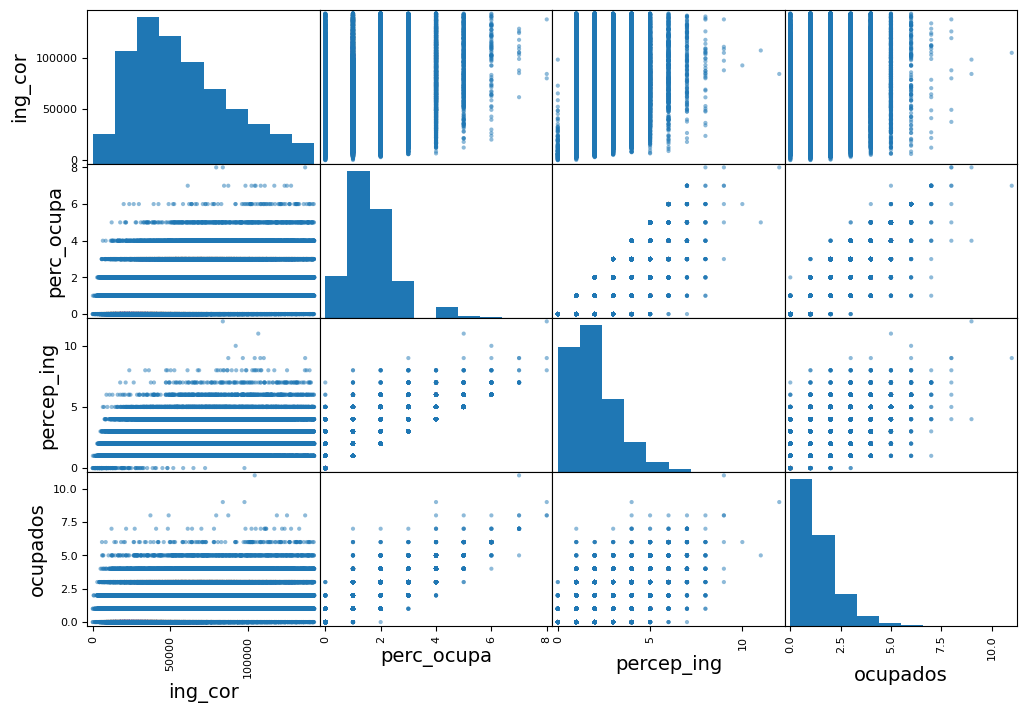

In [41]:
atributos = ['ing_cor', 'perc_ocupa', 'percep_ing', 'ocupados']
scatter_matrix(train_set[atributos], figsize=(12, 8))

## Preparar los datos para los algoritmos de ML

In [45]:
X_train = train_set.drop("ing_cor", axis=1)
y_train = train_set["ing_cor"].copy()
X_test = test_set.drop("ing_cor", axis=1)
y_test = test_set["ing_cor"].copy()

In [47]:
num_pipeline = Pipeline([
    ('imputer', SimpleImputer(strategy="median")),
    ('std_scaler', StandardScaler())
])

cat_pipeline = Pipeline([
    ('imputer_cat', SimpleImputer(strategy="most_frequent")),
    ('onehot', OneHotEncoder(handle_unknown='ignore'))
])

In [48]:
preprocessor = ColumnTransformer([
    ("num", num_pipeline, make_column_selector(dtype_include=['int64', 'float64'])),
    ("cat", cat_pipeline, make_column_selector(dtype_include=['object'])),
    ("drop", "drop", ['folioviv', 'foliohog','ubica_geo'])
    ])
                                 

In [50]:
lin_reg = make_pipeline(preprocessor, LinearRegression())
lin_reg.fit(X_train, y_train)

,"steps steps: list of tuplesList of (name of step, estimator) tuples that are to be chained insequential order. To be compatible with the scikit-learn API, all stepsmust define `fit`. All non-last steps must also define `transform`. See:ref:`Combining Estimators ` for more details.","[('columntransformer', ...), ('linearregression', ...)]"
,"transform_input transform_input: list of str, default=NoneThe names of the :term:`metadata` parameters that should be transformed by thepipeline before passing it to the step consuming it.This enables transforming some input arguments to ``fit`` (other than ``X``)to be transformed by the steps of the pipeline up to the step which requiresthem. Requirement is defined via :ref:`metadata routing `.For instance, this can be used to pass a validation set through the pipeline.You can only set this if metadata routing is enabled, which youcan enable using ``sklearn.set_config(enable_metadata_routing=True)``... versionadded:: 1.6",None
,"memory memory: str or object with the joblib.Memory interface, default=NoneUsed to cache the fitted transformers of the pipeline. The last stepwill never be cached, even if it is a transformer. By default, nocaching is performed. If a string is given, it is the path to thecaching directory. Enabling caching triggers a clone of the transformersbefore fitting. Therefore, the transformer instance given to thepipeline cannot be inspected directly. Use the attribute ``named_steps``or ``steps`` to inspect estimators within the pipeline. Caching thetransformers is advantageous when fitting is time consuming. See:ref:`sphx_glr_auto_examples_neighbors_plot_caching_nearest_neighbors.py`for an example on how to enable caching.",None
,"verbose verbose: bool, default=FalseIf True, the time elapsed while fitting each step will be printed as itis completed.",False
,"transformers transformers: list of tuplesList of (name, transformer, columns) tuples specifying thetransformer objects to be applied to subsets of the data.name : str Like in Pipeline and FeatureUnion, this allows the transformer and its parameters to be set using ``set_params`` and searched in grid search.transformer : {'drop', 'passthrough'} or estimator Estimator must support :term:`fit` and :term:`transform`. Special-cased strings 'drop' and 'passthrough' are accepted as well, to indicate to drop the columns or to pass them through untransformed, respectively.columns : str, array-like of str, int, array-like of int, array-like of bool, slice or callable Indexes the data on its second axis. Integers are interpreted as positional columns, while strings can reference DataFrame columns by name. A scalar string or int should be used where ``transformer`` expects X to be a 1d array-like (vector), otherwise a 2d array will be passed to the transformer. A callable is passed the input data `X` and can return any of the above. To select multiple columns by name or dtype, you can use :obj:`make_column_selector`.","[('num', ...), ('cat', ...), ...]"
,"remainder remainder: {'drop', 'passthrough'} or estimator, default='drop'By default, only the specified columns in `transformers` aretransformed and combined in the output, and the non-specifiedcolumns are dropped. (default of ``'drop'``).By specifying ``remainder='passthrough'``, all remaining columns thatwere not specified in `transformers`, but present in the data passedto `fit` will be automatically passed through. This subset of columnsis concatenated with the output of the transformers. For dataframes,extra columns not seen during `fit` will be excluded from the outputof `transform`.By setting ``remainder`` to be an estimator, the remainingnon-specified columns will use the ``remainder`` estimator. Theestimator must support :term:`fit` and :term:`transform`.Note that using this feature requires that the DataFrame columnsinput at :term:`fit` and :term:`transform` have identical order.",'drop'
,"sparse_threshold sparse_threshold: float, default=0.3If the output of the diff

In [51]:
lin_pred = lin_reg.predict(X_train)
lin_pred[:5]

array([71583.69476425, 89798.36680968, 73298.92753135, 96726.73222917,
       70622.25146076])

In [52]:
y_train[:5]

0    138232.38
1    118014.04
2     46866.32
3    110430.10
4     99494.12
Name: ing_cor, dtype: float64

In [54]:
lin_rmse = root_mean_squared_error(y_train, lin_pred)
lin_mae = mean_absolute_error(y_train, lin_pred)
lin_r2 = r2_score(y_train, lin_pred)

scores = pd.DataFrame({
    "RMSE": [lin_rmse],
    "MAE": [lin_mae],
    "R2": [lin_r2]
    })

scores.head()

,RMSE,MAE,R2
0,24622.572428,19207.105997,0.399679


In [57]:
tree_reg = make_pipeline(preprocessor, DecisionTreeRegressor(random_state=42))

tree_reg.fit(X_train, y_train)

tree_pred = tree_reg.predict(X_train)

tree_rmse = root_mean_squared_error(y_train, tree_pred)
tree_mae = mean_absolute_error(y_train, tree_pred)

scores_tree = pd.DataFrame({
    "RMSE": [tree_rmse],
    "MAE": [tree_mae]
    })

scores_tree.head()

,RMSE,MAE
0,346.570572,5.992013


In [ ]:
param_grid = {
    'max_depth': [3, 5, 10, 15, 20, None],
    'min_samples_split': [2, 10, 20, 50],
    'min_samples_leaf': [1, 5, 10, 20],
    'max_features': [None, 'sqrt', 'log2']
}